# Лекция 4. SARSA и прогулка по обрыву: кто ходит и чью ценность учим

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/IlyaChichkanov/Reinforcement-learning/blob/main/04-sarsa/lecture/lecture.ipynb)

**Главный вопрос сегодня: чью ценность учит агент, который сам же ходит с ошибками?**

Карта пути простая. Лекция 2 дала два уравнения Беллмана — для стратегии и для оптимума. Лекция 3 научила решать второе по попыткам — получился Q-learning. Сегодня тем же способом решаем первое — получится **SARSA**, который на той же среде с теми же настройками выучивает *другой* путь. Разница между ними — это ответ на вопрос «чью ценность учит агент, который сам ходит с ошибками».

Лекция устроена не как обычно: почти каждый раздел начинается с вопроса, на который мы **голосуем всей аудиторией**, и только потом проверяем ответ запуском. Вопросы и песочница сегодняшней среды — на странице-спутнике, откройте её на телефоне:

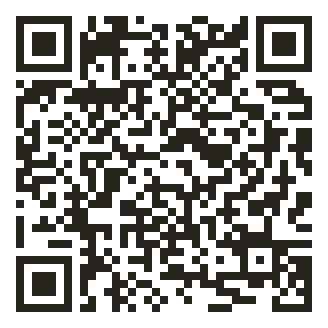

[ilyachichkanov.github.io/Reinforcement-learning/lecture04.html](https://ilyachichkanov.github.io/Reinforcement-learning/lecture04.html)

| | Раздел | Минут |
|---|---|---|
| 1 | 🔁 Q-learning за три вопроса | 12 |
| 2 | Новая среда: прогулка по обрыву | 10 |
| 3 | SARSA: в цели то, что агент сделает | 18 |
| 4 | Эксперимент: обрыв рассудит | 15 |
| 5 | On-policy и off-policy: две роли стратегии | 8 |
| 6 | Что на самом деле делает SARSA | 12 |
| 7 | ⏱ Expected SARSA и завышающий максимум | 9 |
| 8 | Итоги и где это работает | 6 |

Пометки: **🔁** — вспоминаем пройденное, **⏱** — резерв, если останется время. Служебный код лежит в `gridworld.py`, `gridworld_plots.py` и `td_plots.py` (все — из прошлых лекций); читать его не нужно.

In [1]:
# Служебные модули прошлых лекций. Локально они уже в репозитории, в Google Colab — скачиваются.
import pathlib, sys, urllib.request
sys.path.append("../../02-environments/lecture")
sys.path.append("../../03-value-based/lecture")
REPO = "https://raw.githubusercontent.com/IlyaChichkanov/Reinforcement-learning/main/"
for path in ["02-environments/lecture/gridworld.py", "02-environments/lecture/gridworld_plots.py",
             "03-value-based/lecture/td_plots.py"]:
    name = pathlib.Path(path).name
    if not pathlib.Path(name).exists() and not pathlib.Path("../..", path).exists():
        urllib.request.urlretrieve(REPO + path, name)

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
from gridworld import *          # GridWorld, mdp_matrices, solve_q_star, uniform_policy, GAMMA
from gridworld_plots import *    # plot_values, draw_policy
from td_plots import *           # draw_cliff, greedy_path, plot_curves

env = GridWorld()                # клетчатый мир лекций 2–3: 3 × 4, ветер 0.8 / 0.1 / 0.1, −0.04 за шаг
P, R = mdp_matrices(env)         # модель среды — сегодня только чтобы сверять ответы
Q_star = solve_q_star(P, R)      # эталон из лекции 2
V_star = Q_star.max(axis=1)

## 1. 🔁 Q-learning за три вопроса

Вся прошлая лекция помещается в одну строку: **новая оценка = старая + $\alpha$ · (цель − старая)**, а цель Q-learning — правая часть уравнения оптимальности, собранная из одного реального перехода:

$$
Q(s,a) \;\leftarrow\; Q(s,a) \;+\; \alpha\,\big(\underbrace{r + \gamma \max_{a'} Q(s',a')}_{\text{цель}} \;-\; Q(s,a)\big)
$$

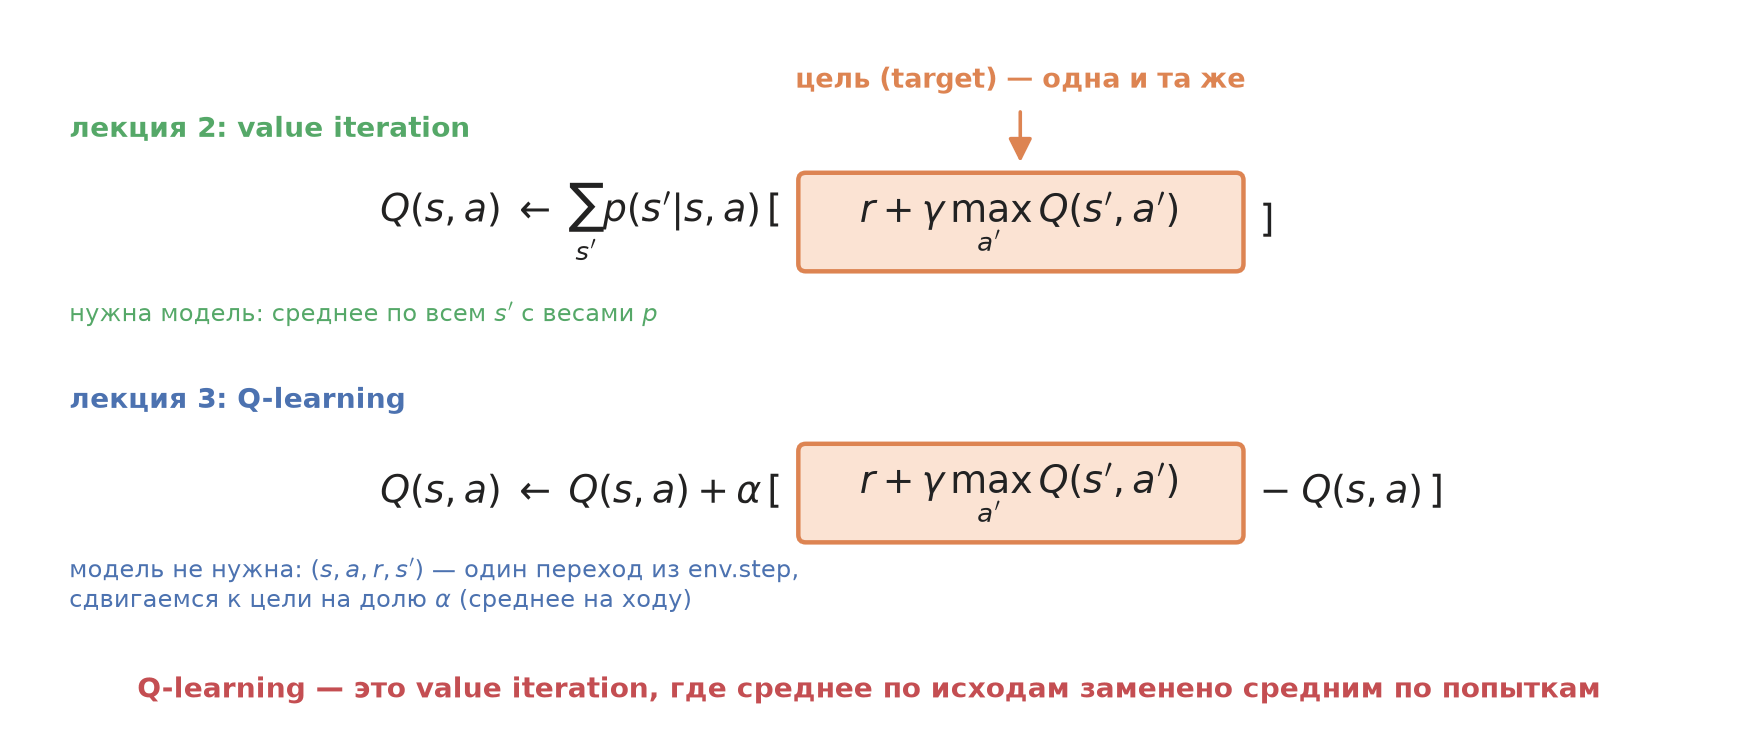

Прежде чем идти дальше, проверим, что эта строка действительно в руках. Три вопроса, числа в каждом считаются в уме. На каждый сначала **голосуем** — потом проверяем запуском.

**Вопрос 1.** Агент стоит в клетке $s$. Строка таблицы: $Q(s, \leftarrow) = +0.10$, $Q(s, \downarrow) = -1.00$, $Q(s, \rightarrow) = +0.20$, $Q(s, \uparrow) = +0.40$. Куда пойдёт жадная стратегия?

**Вопрос 2.** Оценка $Q(s,a) = 0.30$, цель этого шага — $0.50$, $\alpha = 0.1$. Какой станет оценка после одного обновления?

**Вопрос 3.** $\varepsilon = 0.2$, действий четыре, лучшее по таблице — $\uparrow$. С какой вероятностью $\varepsilon$-жадный агент шагнёт $\uparrow$?

In [3]:
q_row = {"←": +0.10, "↓": -1.00, "→": +0.20, "↑": +0.40}
print("вопрос 1: жадная стратегия идёт", max(q_row, key=q_row.get))

q, target, alpha = 0.30, 0.50, 0.1
print(f"вопрос 2: {q} + {alpha} · ({target} − {q}) = {q + alpha * (target - q):.2f}")

def epsilon_greedy(Q, s, eps, rng):
    """С вероятностью ε — случайное действие, иначе лучшее по Q (ничьи — случайно)."""
    if rng.random() < eps:
        return int(rng.integers(Q.shape[1]))
    return int(rng.choice(np.flatnonzero(Q[s] == Q[s].max())))

rng = np.random.default_rng(0)
Q_demo = np.array([list(q_row.values())])             # та же строка таблицы; лучшее действие — ↑, номер 3
freq = np.mean([epsilon_greedy(Q_demo, 0, eps=0.2, rng=rng) == 3 for _ in range(100_000)])
print(f"вопрос 3: доля шагов ↑ из 100 000 розыгрышей: {freq:.3f}   (в уме: 0.8 + 0.2/4 = 0.85)")

вопрос 1: жадная стратегия идёт ↑
вопрос 2: 0.3 + 0.1 · (0.5 − 0.3) = 0.32


вопрос 3: доля шагов ↑ из 100 000 розыгрышей: 0.849   (в уме: 0.8 + 0.2/4 = 0.85)


Три ответа — это и есть весь механизм прошлой лекции:

* **жадный выбор** — argmax по строке таблицы;
* **обновление** — сдвиг старой оценки к цели на долю $\alpha$, вот он на числовой прямой:

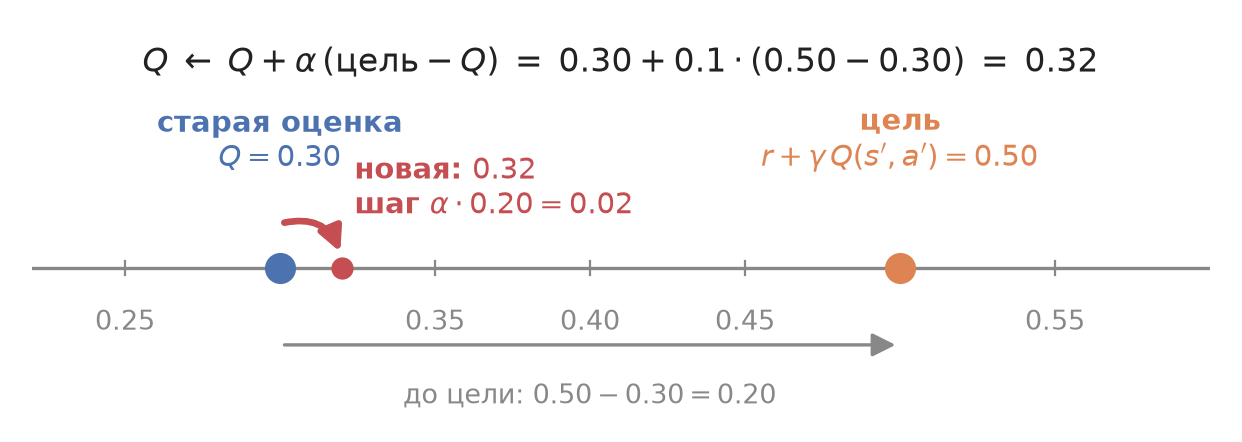

* **ходит агент не жадно, а $\varepsilon$-жадно** — иначе про действия, которые он ни разу не пробовал, таблица так ничего и не узнает:

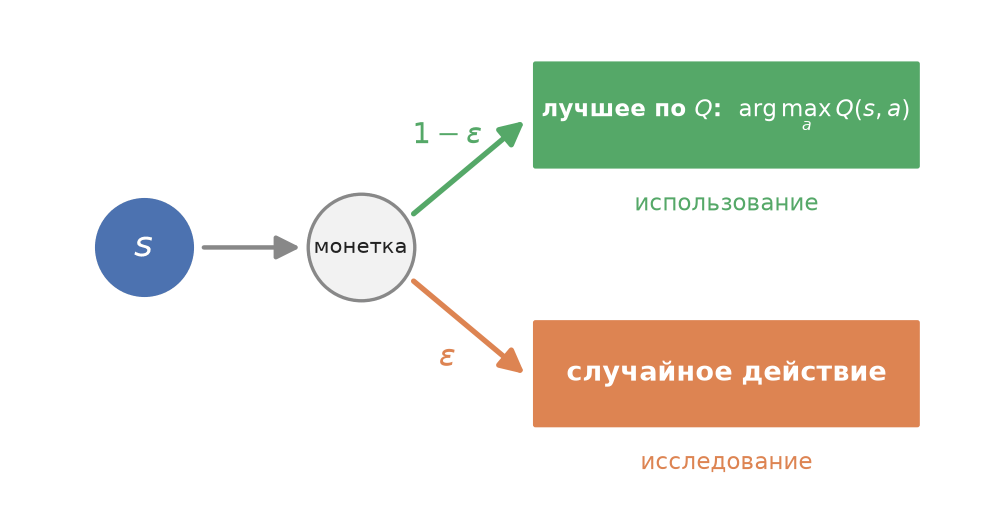

На третий вопрос стоит посмотреть ещё раз: даже у «почти жадного» агента $(100 - 85)\% = 15\%$ шагов идут не в лучшую сторону. Сегодня это маленькое число станет главным героем.

**Одной строкой:** сдвигай оценку к цели $r + \gamma \max_{a'} Q(s',a')$ на долю $\alpha$, а ходи $\varepsilon$-жадно.

## 2. Новая среда: прогулка по обрыву

В клетчатом мире прошлых лекций ошибка стоила дёшево: лишний шаг — и всё. Сегодня нужна среда, где **цена ошибки видна глазом**. Это Cliff Walking из Gymnasium: поле 4 × 12, старт слева внизу, выход справа внизу, между ними — обрыв.

Правила простые:

* каждый шаг — награда $-1$: чем короче путь, тем больше return;
* шаг в обрыв — награда $-100$ и возврат на старт, **эпизод продолжается**;
* $\gamma = 1$: эпизод конечный, обесценивать будущее не нужно.

**Вопрос 4 (голосуем).** Какой наибольший return вообще возможен в этой среде: $-17$, $-13$, $0$ или $-1$?

Ответ — на карте. Кратчайший путь от S до G идёт **вдоль самого края** и занимает 13 шагов: return $-13$. Больше не бывает: даром по этой среде не ходят. Запасной вариант — обход поверху, 17 шагов:

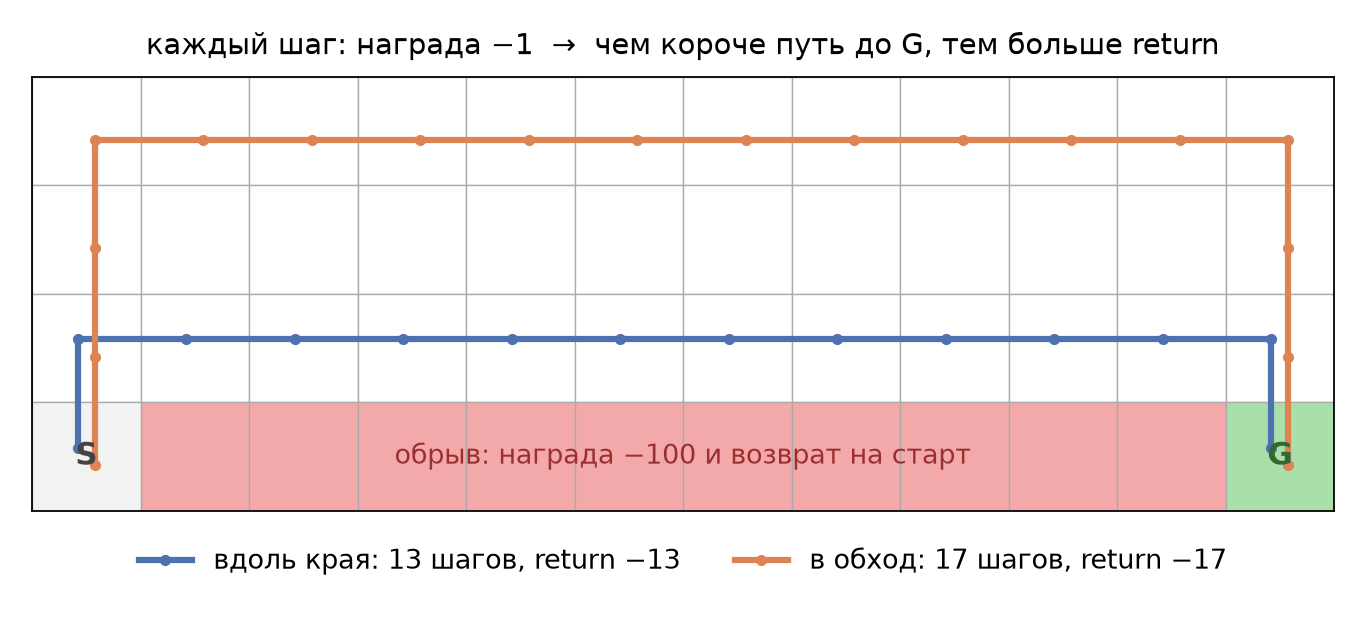

А вот как по этой среде ходит агент, который ещё ничему не научился:

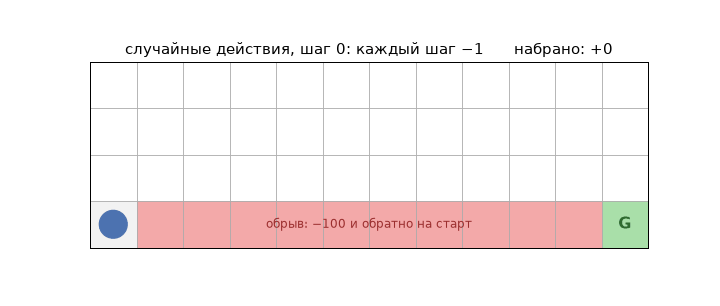

Проверим числом, сколько случайная стратегия набирает за сто шагов.

In [4]:
cliff = gym.make("CliffWalking-v1")
print("состояний:", cliff.observation_space.n, "  действий:", cliff.action_space.n)

rng = np.random.default_rng(0)
s, _ = cliff.reset(seed=0)
total, falls = 0, 0
for t in range(100):
    s, r, terminated, truncated, _ = cliff.step(int(rng.integers(4)))   # действия наугад
    total += r
    falls += r == -100
    if terminated or truncated:
        break
print(f"случайная стратегия, 100 шагов: срывов {falls}, набрано {total:+.0f}, до G так и не дошла")

состояний: 48   действий: 4
случайная стратегия, 100 шагов: срывов 20, набрано -2080, до G так и не дошла


Минус две тысячи за сто шагов — есть куда расти. Заодно видно, из чего складывается счёт: двадцать срывов по $-100$ дают $-2000$, остальное — по $-1$ за шаг.

**Одной строкой:** обрыв делает цену ошибки измеримой — $-1$ за шаг против $-100$ за срыв.

## 3. SARSA: в цели то, что агент сделает

В цели Q-learning стоит $\max_{a'}$ — «дальше я сыграю идеально». Но мы только что посчитали: даже почти жадный агент делает 15% шагов не в лучшую сторону. **SARSA** подставляет в цель не лучшее действие, а то действие $a'$, которое агент *действительно сделает* на следующем шаге. Вся разница — в одной букве:

$$
\text{цель Q-learning} = r + \gamma \max_{a'} Q(s',a')
\qquad\qquad
\text{цель SARSA} = r + \gamma\, Q(s', a')
$$

где $a'$ уже выбрано $\varepsilon$-жадной стратегией — вместе с её случайными шагами. Имя алгоритма — это пятёрка, по которой он учится: $s, a, r, s', a'$ — **S–A–R–S–A**.

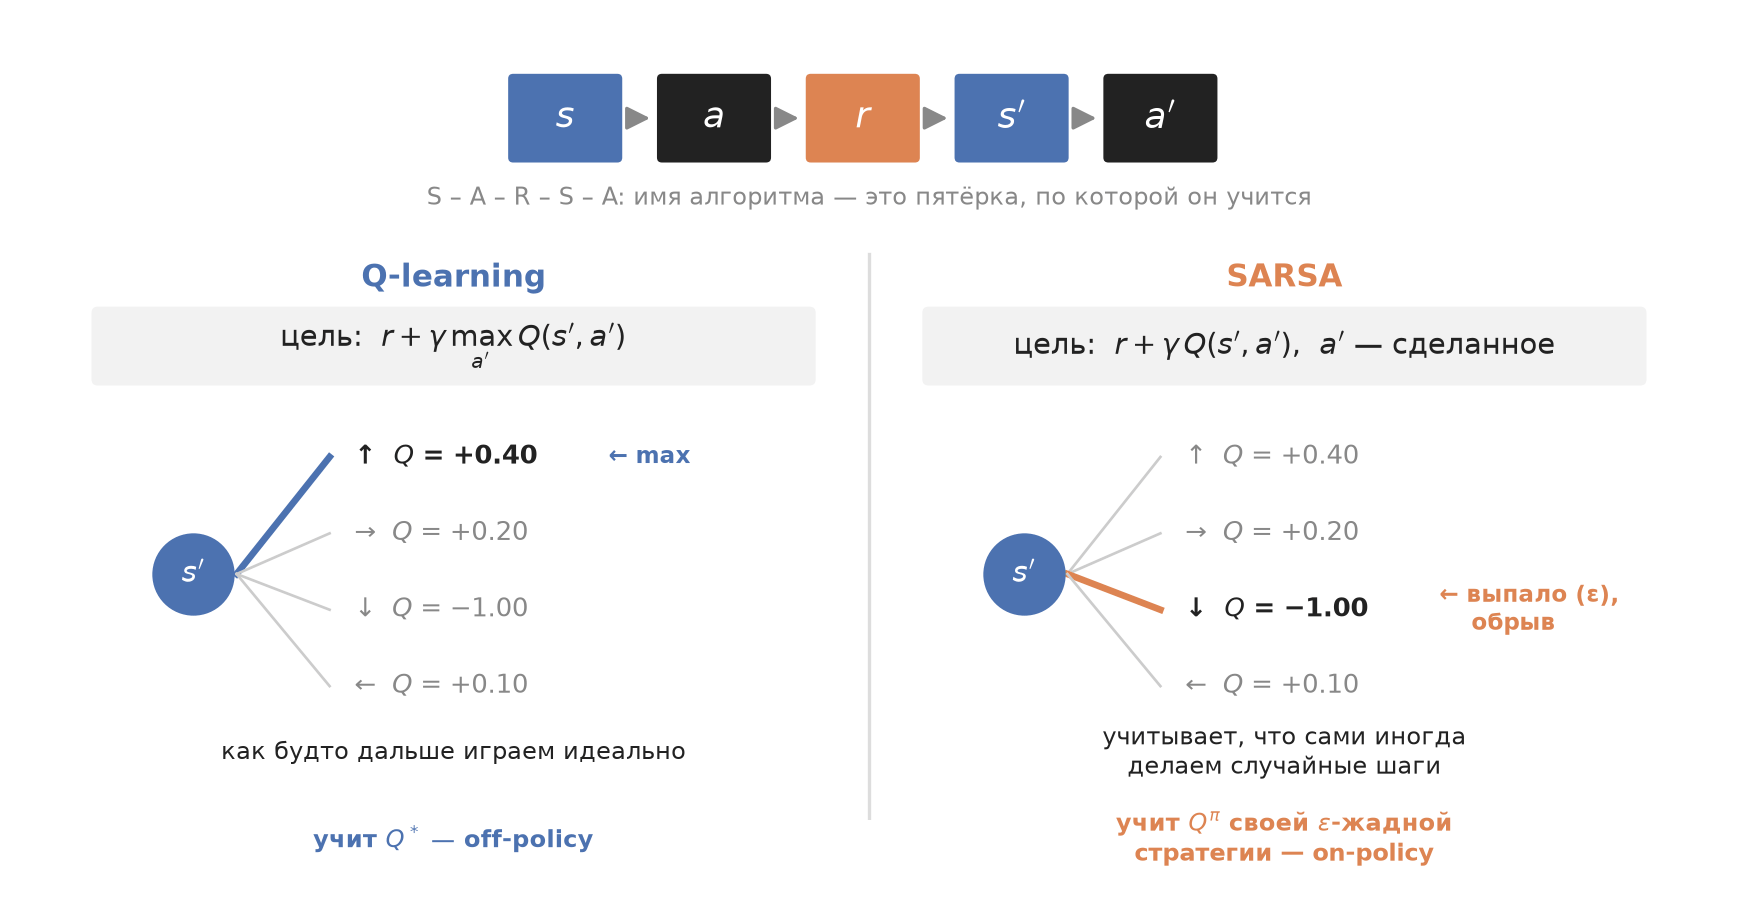

🔁 За каждой целью стоит своё уравнение лекции 2 — оба нам знакомы.

Цель SARSA — выборочная версия уравнения **для конкретной стратегии** $\pi$; эта $\pi$ — его же собственная $\varepsilon$-жадная:

$$
Q^\pi(s,a) = \sum_{s'} p(s' \mid s,a)\,\Big[\, r + \gamma \sum_{a'} \pi(a' \mid s')\, Q^\pi(s',a') \,\Big]
$$

Цель Q-learning — выборочная версия уравнения **оптимальности**:

$$
Q^*(s,a) = \sum_{s'} p(s' \mid s,a)\,\Big[\, r + \gamma \max_{a'} Q^*(s',a') \,\Big]
$$

Первое отвечает на вопрос «сколько наберёт именно эта стратегия», второе — «сколько наберёт лучшая». Поэтому SARSA учит $Q^\pi$, а Q-learning — $Q^*$.

**Вопрос 5 — главный в лекции (голосуем).** Пустим оба алгоритма на обрыв: $\varepsilon = 0.1$, $\alpha = 0.5$, 500 эпизодов. Какой путь выучит каждый?

* A — оба выучат путь вдоль края;
* B — оба выучат обход;
* C — Q-learning пойдёт вдоль края, SARSA — в обход;
* D — Q-learning пойдёт в обход, SARSA — вдоль края.

Прежде чем проверять — код. Оба алгоритма (и Expected SARSA из раздела 6) помещаются в одну функцию: различие — одна строка «что подставить вместо будущего».

In [5]:
def td_control(env, kind, n_episodes=500, alpha=0.5, eps=0.1, gamma=1.0, seed=0, max_steps=500):
    """Q-learning, SARSA и Expected SARSA для среды Gymnasium с дискретными состояниями."""
    rng = np.random.default_rng(seed)
    Q = np.zeros((env.observation_space.n, env.action_space.n))
    returns = []
    for episode in range(n_episodes):
        s, _ = env.reset(seed=int(rng.integers(1_000_000)))
        a = epsilon_greedy(Q, s, eps, rng)
        total = 0.0
        for t in range(max_steps):
            s_next, r, terminated, truncated, _ = env.step(a)
            a_next = epsilon_greedy(Q, s_next, eps, rng)   # следующее действие выбираем сразу: это a' из пятёрки
            if kind == "q-learning":
                future = Q[s_next].max()                   # цель: r + γ max Q(s',·) — «дальше играю идеально»
            elif kind == "sarsa":
                future = Q[s_next, a_next]                 # цель: r + γ Q(s',a') — «дальше играю как играю»
            else:                                          # "expected sarsa" — раздел 6
                probs = np.full(env.action_space.n, eps / env.action_space.n)
                probs[Q[s_next].argmax()] += 1 - eps
                future = probs @ Q[s_next]                 # цель: r + γ Σ π(a'|s') Q(s',a') — среднее по стратегии
            Q[s, a] += alpha * (r + gamma * (0.0 if terminated else future) - Q[s, a])   # сдвиг к цели на долю α
            total += r
            s, a = s_next, a_next
            if terminated or truncated:
                break
        returns.append(total)
    return Q, np.array(returns)

## 4. Эксперимент: обрыв рассудит

Запускаем оба алгоритма по десять раз — чтобы отличить закономерность от везения одного запуска.

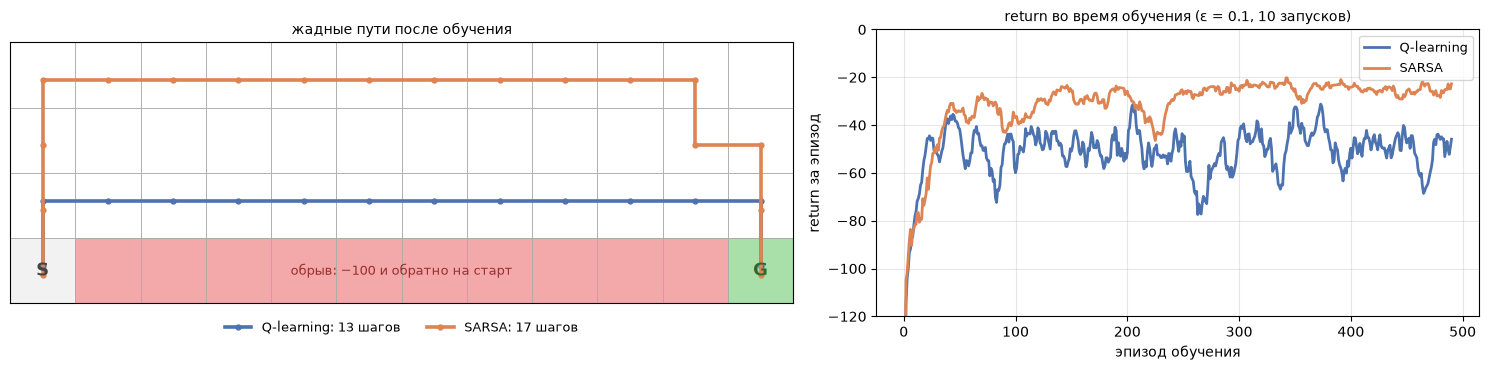

Q-learning: жадный путь доходит до G в 10 запусках из 10, длина 13 шагов; return при обучении (последние 100 эпизодов) -50.2
     SARSA: жадный путь доходит до G в 8 запусках из 10, длина 17 шагов; return при обучении (последние 100 эпизодов) -25.3


In [6]:
runs = {"Q-learning": [td_control(cliff, "q-learning", seed=seed) for seed in range(10)],
        "SARSA": [td_control(cliff, "sarsa", seed=seed) for seed in range(10)]}

SHOW = 2                                              # какой из десяти запусков нарисовать
fig, axes = plt.subplots(1, 2, figsize=(15, 3.8), gridspec_kw={"width_ratios": [1.3, 1]})
draw_cliff({name: greedy_path(r[SHOW][0]) for name, r in runs.items()}, ax=axes[0], title="жадные пути после обучения")
plot_curves({name: [ret for _, ret in r] for name, r in runs.items()}, ax=axes[1],
            title="return во время обучения (ε = 0.1, 10 запусков)")
plt.tight_layout(); plt.show()

for name, r in runs.items():
    paths = [greedy_path(Q) for Q, _ in r]
    reached = [len(p) - 1 for p in paths if p[-1] == CLIFF_GOAL]
    steps = f"{min(reached)}" if min(reached) == max(reached) else f"{min(reached)}–{max(reached)}"
    print(f"{name:>10}: жадный путь доходит до G в {len(reached)} запусках из 10, длина {steps} шагов; "
          f"return при обучении (последние 100 эпизодов) {np.mean([ret[-100:].mean() for _, ret in r]):+.1f}")

Прогноз из вопроса 5 можно сверить с запуском. Два разных ответа на вопрос «как правильно»:

* **Q-learning** выучил кратчайший путь по самому краю — 13 шагов, во всех десяти запусках. Для агента без ошибок этот путь лучший. Но учится агент $\varepsilon$-жадно, и случайный шаг у края время от времени сбрасывает его в обрыв: return при обучении около $-50$.
* **SARSA** выучил обход по верхнему ряду — 17 шагов. Путь длиннее, зато случайный шаг там не страшен: return при обучении около $-25$, вдвое лучше. В двух запусках из десяти его жадная стратегия где-то упирается в стену: при постоянном $\alpha = 0.5$ оценки дрожат — помогает уменьшать со временем $\alpha$ или $\varepsilon$.

**Почему так выходит?** Проследим, как штраф попадает в таблицу. Агент стоит у края и делает шаг вправо — тоже вдоль края. В цель SARSA подставляется следующее действие $a'$, **которое агент реально выбрал**. Обычно это снова «вправо», но раз в несколько десятков шагов $\varepsilon$-жадность выбрасывает случайное «вниз» — и тогда в цель приезжает оценка $Q(s', \text{вниз}) \approx -100$. Так штраф за *возможную будущую ошибку* протекает в оценку самого хождения вдоль края. Q-learning в той же ситуации берёт $\max_{a'} Q(s', a')$ — лучшее действие из $s'$, — и «вниз» в его цель не попадает никогда: край для него чист.

Осталось сравнить цены. При $\varepsilon = 0.1$ случайным оказывается каждый десятый шаг, и в четверти случаев это шаг вниз: примерно **один шанс из сорока улететь на $-100$** — в среднем около $-2.5$ сверху на каждый шаг вдоль края, а таких шагов одиннадцать: порядка $-27$ ожидаемого штрафа. Обход стоит всего **4 лишних шага**, то есть $-4$. Для агента, который ошибается, обход честно выгоднее — и SARSA видит это в собственных данных, потому что учит ценность себя настоящего, а не себя идеального.

Как они к этому пришли — по эпизодам:

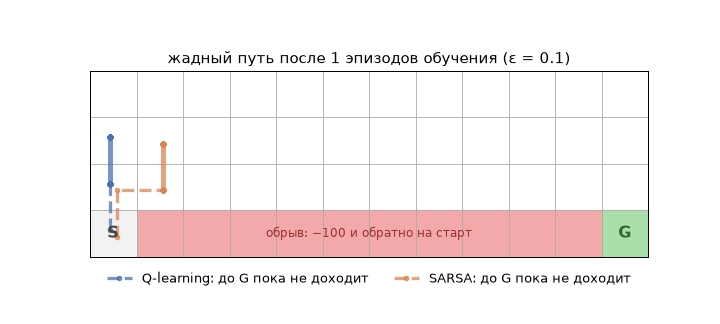

Обратите внимание на 160-й эпизод: путь SARSA на мгновение теряется — это та самая дрожь оценок при большом $\alpha$, к 250-му эпизоду путь восстанавливается.

Кто прав? Зависит от вопроса. Если после обучения случайность выключат — лучше путь Q-learning. Если агент и дальше будет иногда ошибаться (робот с неточными моторами, трейдер с проскальзыванием) — путь SARSA.

**Эксперимент себе (две минуты, вопрос 6 на странице).** В ячейке выше замените параметры на `eps=0.01, alpha=0.1, n_episodes=2000` и перезапустите — или подвигайте ползунки в [песочнице](https://ilyachichkanov.github.io/Reinforcement-learning/lecture04.html#sandbox). Путь SARSA спустится с верхнего ряда на средний: 15 шагов. Случайных шагов почти нет — и осторожность почти перестала окупаться.

**Одной строкой:** SARSA набирает при обучении примерно вдвое больше, потому что учит ценность своей $\varepsilon$-жадной стратегии — вместе с её ошибками.

## 5. On-policy и off-policy: две роли стратегии

На обрыве оба агента **ходили одинаково** — $\varepsilon$-жадно, с одним и тем же $\varepsilon$. А выучили разное. Значит, у стратегии в обучении две роли:

* **стратегия поведения** — та, что ходит по среде и собирает переходы $(s, a, r, s')$;
* **целевая стратегия** — та, чью ценность мы учим. Она спрятана в цели обновления: какое действие подставляем в $s'$.

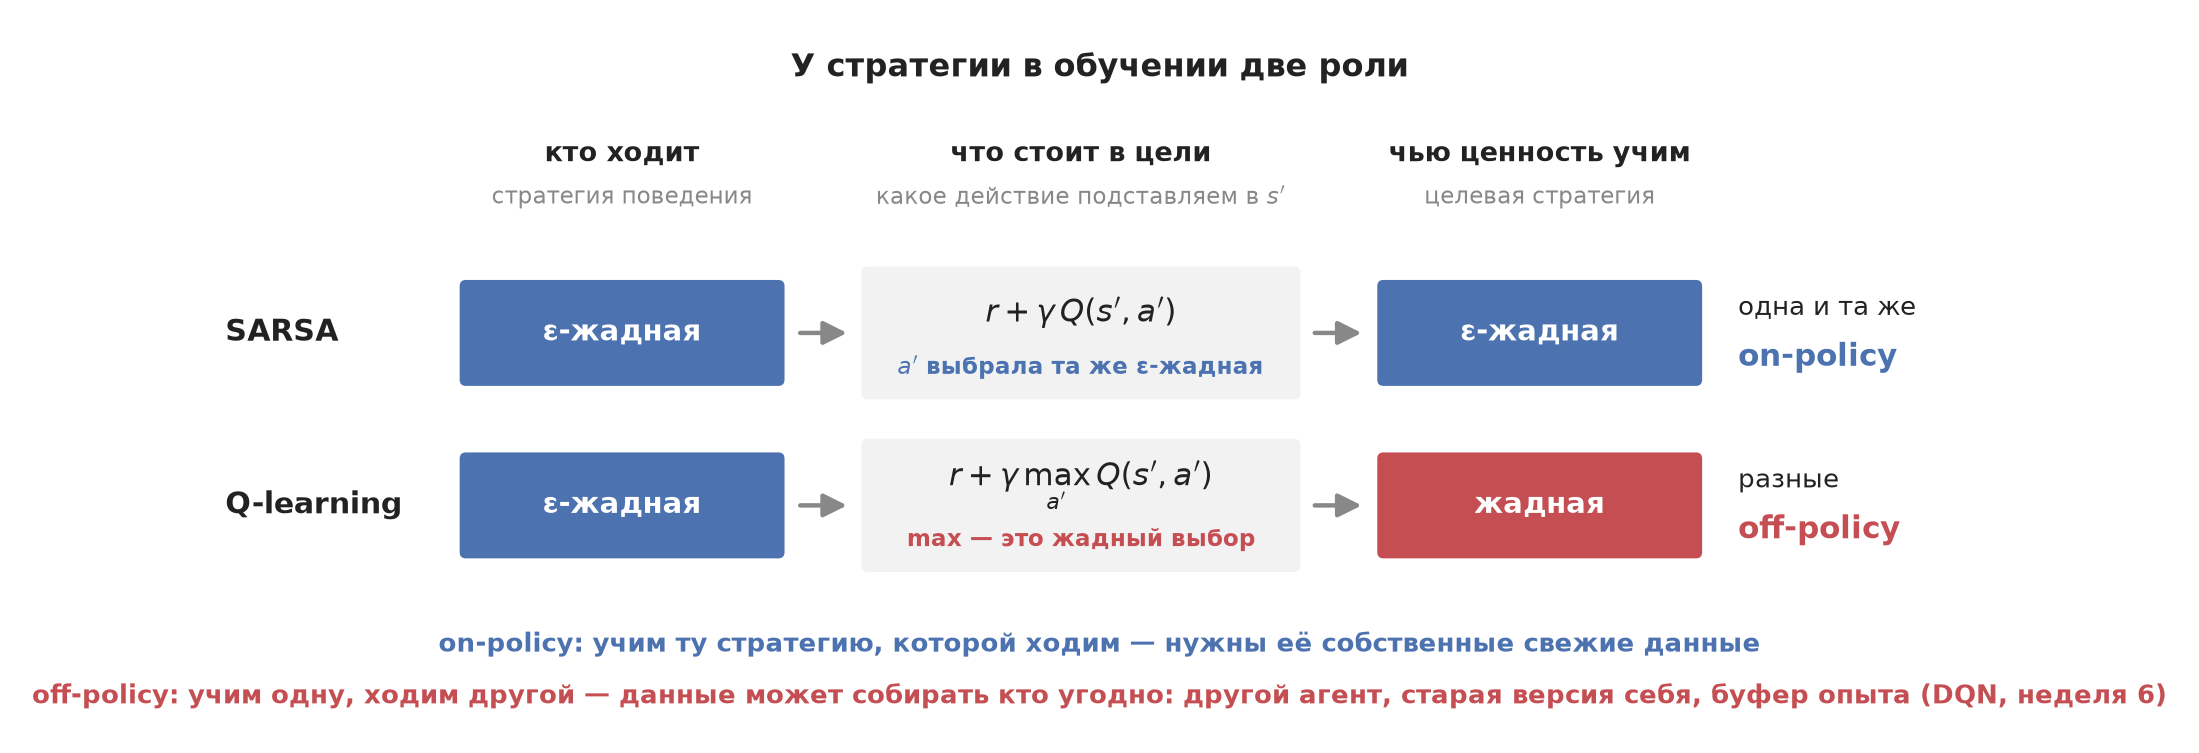

Роли совпали — алгоритм **on-policy**. Разошлись — **off-policy**.

Пример из жизни. Рекомендательный сервис переобучается на логах кликов, которые собрала **прошлая** версия рекомендаций: ходила одна стратегия, а ценность учим для новой — это off-policy. On-policy-алгоритму такие логи не годятся: ему нужны свежие действия его собственной стратегии.

Проверим это на клетчатом мире — буквально как в примере с логами. Сначала **соберём набор данных**: случайная стратегия, которая выбирает каждое действие наугад с равными вероятностями, сыграет 3000 эпизодов, и каждый переход мы запишем пятёркой $(s, a, r, s', a')$ в список `log`. Потом **оба алгоритма обучатся по одному и тому же списку** — переход за переходом, в одном общем цикле. Вся разница между ними, как и весь сегодняшний день, — одна строка: что подставить вместо будущего.

**Прогноз (голосуем руками).** Что выучит Q-learning по такому логу: ценность случайной стратегии, которая его собирала, — или ценность лучшей?

Сравнивать будем честно — **одной и той же меркой для всех**. У нас есть две точные таблицы: $Q^*$ лучшей стратегии (лекция 2) и $Q^\pi$ самой случайной стратегии (посчитаем её уравнением для $\pi$ оттуда же). Для каждой выученной таблицы измерим среднюю ошибку $|Q_\text{выученная} - Q_\text{эталон}|$ против **обоих** эталонов — и посмотрим, к какому она прижалась.

в логе 94142 переходов; первые два: [(8, 2, -0.04, 9, 2, False), (9, 2, -0.04, 10, 1, False)]


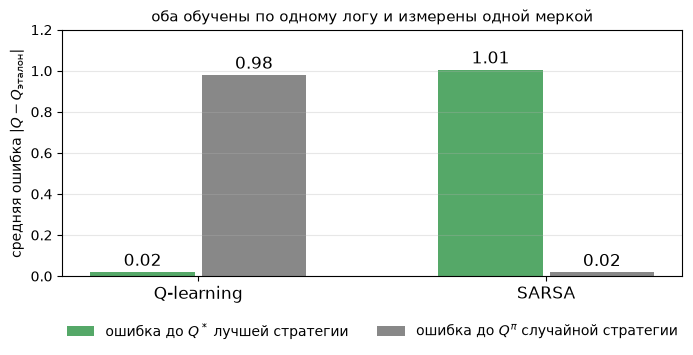

In [7]:
# --- шаг 1: случайная стратегия собирает лог из пятёрок (s, a, r, s', a') ---
rng = np.random.default_rng(0)
log = []
for episode in range(3000):
    s, _ = env.reset(seed=int(rng.integers(1_000_000)))
    a = int(rng.integers(4))                            # действие наугад
    for t in range(100):
        s2, r, terminated, truncated, _ = env.step(a)
        a2 = int(rng.integers(4))                       # и следующее действие тоже наугад
        log.append((s, a, r, s2, a2, terminated))
        s, a = s2, a2
        if terminated or truncated:
            break
print(f"в логе {len(log)} переходов; первые два: {log[:2]}")

# --- шаг 2: один проход по логу — два правила обновления, вся разница в одной строке ---
alpha = 0.05
Q_ql, Q_sarsa = np.zeros_like(R), np.zeros_like(R)
for s, a, r, s2, a2, done in log:
    future_ql    = 0.0 if done else Q_ql[s2].max()      # Q-learning: лучшее следующее действие
    future_sarsa = 0.0 if done else Q_sarsa[s2, a2]     # SARSA: действие, записанное в логе
    Q_ql[s, a]    += alpha * (r + GAMMA * future_ql    - Q_ql[s, a])
    Q_sarsa[s, a] += alpha * (r + GAMMA * future_sarsa - Q_sarsa[s, a])

# --- шаг 3: одна мерка против двух эталонов ---
random_policy = uniform_policy(env)
Q_pi = np.zeros_like(R)                                 # точная Q случайной стратегии: уравнение для π, лекция 2
for _ in range(300):
    Q_pi = R + GAMMA * (P @ (random_policy * Q_pi).sum(axis=1))
cells = [s for s in range(env.n_states) if not env.is_wall(s) and not env.is_terminal(s)]
err = lambda Q, ref: np.abs(Q - ref)[cells].mean()      # средняя ошибка таблицы — одинаковая для всех

fig, ax = plt.subplots(figsize=(8, 3.2))
for shift, ref, name, color in [(-0.16, Q_star, "ошибка до $Q^*$ лучшей стратегии", "#55A868"),
                                (+0.16, Q_pi, "ошибка до $Q^\pi$ случайной стратегии", "#888888")]:
    vals = [err(Q_ql, ref), err(Q_sarsa, ref)]
    ax.bar([0 + shift, 1 + shift], vals, width=0.3, color=color, label=name)
    for xi, v in zip([0 + shift, 1 + shift], vals):
        ax.text(xi, v + 0.03, f"{v:.2f}", ha="center", fontsize=12)
ax.set_xticks([0, 1]); ax.set_xticklabels(["Q-learning", "SARSA"], fontsize=12)
ax.set_ylabel("средняя ошибка $|Q - Q_\mathrm{эталон}|$")
ax.set_ylim(0, 1.2); ax.grid(alpha=0.3, axis="y")
ax.legend(fontsize=10, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2, frameon=False)
ax.set_title("оба обучены по одному логу и измерены одной меркой", fontsize=11)
plt.show()

Лог один и тот же, мерка одна и та же — разным было только правило обновления. И каждая таблица прижалась к своему эталону:

* **Q-learning** совпал с $Q^*$: ошибка $0.02$ — при $0.98$ до чужого эталона. По логу случайных блужданий он восстановил ценности **лучшей** стратегии, хотя ни одного разумного шага в данных не было.
* **SARSA** совпал с $Q^\pi$ случайной стратегии: $0.02$ — при $1.01$ до чужого. Он выучил ценность **той стратегии, которая собирала лог**.

Что из этого следует дальше в курсе:

* off-policy-алгоритм может учиться по сохранённому логу чужих переходов — мы только что буквально это сделали; так работает буфер опыта в DQN (он впереди в курсе);
* on-policy-алгоритму нужны свежие данные его собственной стратегии — так устроены policy gradient и PPO (следующие недели).

Теперь понятен и обрыв: SARSA оценивал свою $\varepsilon$-жадную стратегию вместе с её случайными шагами — и ушёл от края; Q-learning оценивал жадную, которая не оступается, — и пошёл по краю.

**Одной строкой:** Q-learning учит ценность жадной стратегии, кто бы ни собирал данные (off-policy); SARSA — ценность той стратегии, которая ходит (on-policy).

## 6. Что на самом деле делает SARSA

Мы научили SARSA ездить — теперь разберём механизм, из-за которого всё это работает. Награду агент **максимизирует**, но внутри каждого обновления сидит **минимизация** — минимизация TD-ошибки. А минимизировать TD-ошибку — значит делать знакомый по лекции 3 шаг «оценить стратегию».

### 6.1 Минимизация — внутри обновления

Для перехода $(s, a, r, s', a')$ цель — это «метка», к которой мы подтягиваем текущую оценку:

$$
y = r + \gamma\, Q(s', a'), \qquad \delta = y - Q(s,a)
$$

Посмотрим на квадрат ошибки как на функцию потерь и возьмём градиент по $Q(s,a)$:

$$
L = \tfrac{1}{2}\,\big(y - Q(s,a)\big)^2, \qquad \frac{\partial L}{\partial Q(s,a)} = -\big(y - Q(s,a)\big) = -\delta
$$

Шаг градиентного спуска по $L$ — в точности наше обновление:

$$
Q(s,a) \;\leftarrow\; Q(s,a) - \alpha\,\frac{\partial L}{\partial Q(s,a)} \;=\; Q(s,a) + \alpha\,\delta
$$

Минимизация сидит **внутри обновления $Q$**, а не в цели: цель — просто метка.

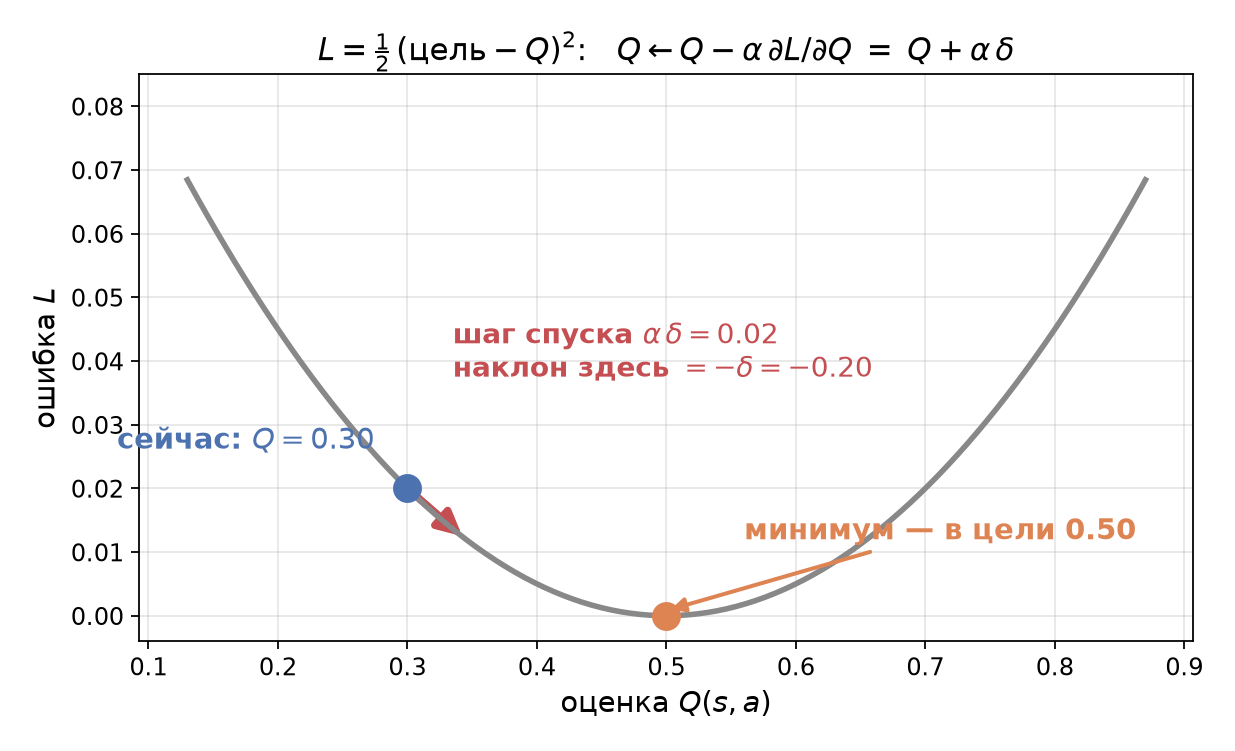

Числа на картинке — из раздела 1: старая оценка $0.30$, цель $0.50$, шаг $0.02$. Одно и то же обновление, снятое с двух ракурсов.

Одна честная оговорка: метка здесь не как в supervised learning — она сама построена из $Q$ и двигается вместе с таблицей, а градиент мы берём только по $Q(s,a)$. Такой спуск называют **semi-gradient**. Когда вместо таблицы появится нейросеть (DQN), ровно эта $L$ станет её loss-функцией.

### 6.2 Минимизировать TD-ошибку — значит оценивать стратегию

Действие $a'$ в цели выбрано той же $\varepsilon$-жадной стратегией $\pi$, которой агент ходит, — значит, цель это выборочная версия уравнения Беллмана **для $\pi$** из раздела 3. Загоняя TD-ошибку в ноль, мы заставляем $Q$ удовлетворять этому уравнению — то есть выполняем **оценку стратегии** (policy evaluation): 🔁 шаг «оценить» из policy iteration лекции 3, только без модели и по попыткам.

Но в policy iteration было два шага. Где второй?

**Вопрос 7 (голосуем).** В цели SARSA нет $\max$. За счёт чего же он улучшает стратегию — находит разумный путь, а не просто оценивает какую-то случайную?

* A — за счёт дисконта $\gamma$;
* B — за счёт argmax внутри $\varepsilon$-жадного выбора действий;
* C — за счёт шага обучения $\alpha$;
* D — он и не улучшает: хороший путь получается сам собой.

Ответ прячется в одной строке кода из раздела 1. Шаг «улучшить» у SARSA — не в цели, а в **выборе действий**:

$$\pi'(s) = \arg\max_a Q(s,a)$$

```python
return int(rng.choice(np.flatnonzero(Q[s] == Q[s].max())))   # ← вот он, max: внутри epsilon_greedy
```

Таблица подросла — и $\varepsilon$-жадная стратегия, которая по ней ходит, уже другая: чуть жаднее к хорошим клеткам. SARSA оценивает её, таблица снова растёт, стратегия снова меняется… 🔁 Это цикл «оценил — улучшил — повторил» из лекции 3, размазанный на микрошаги — по науке **generalized policy iteration**:

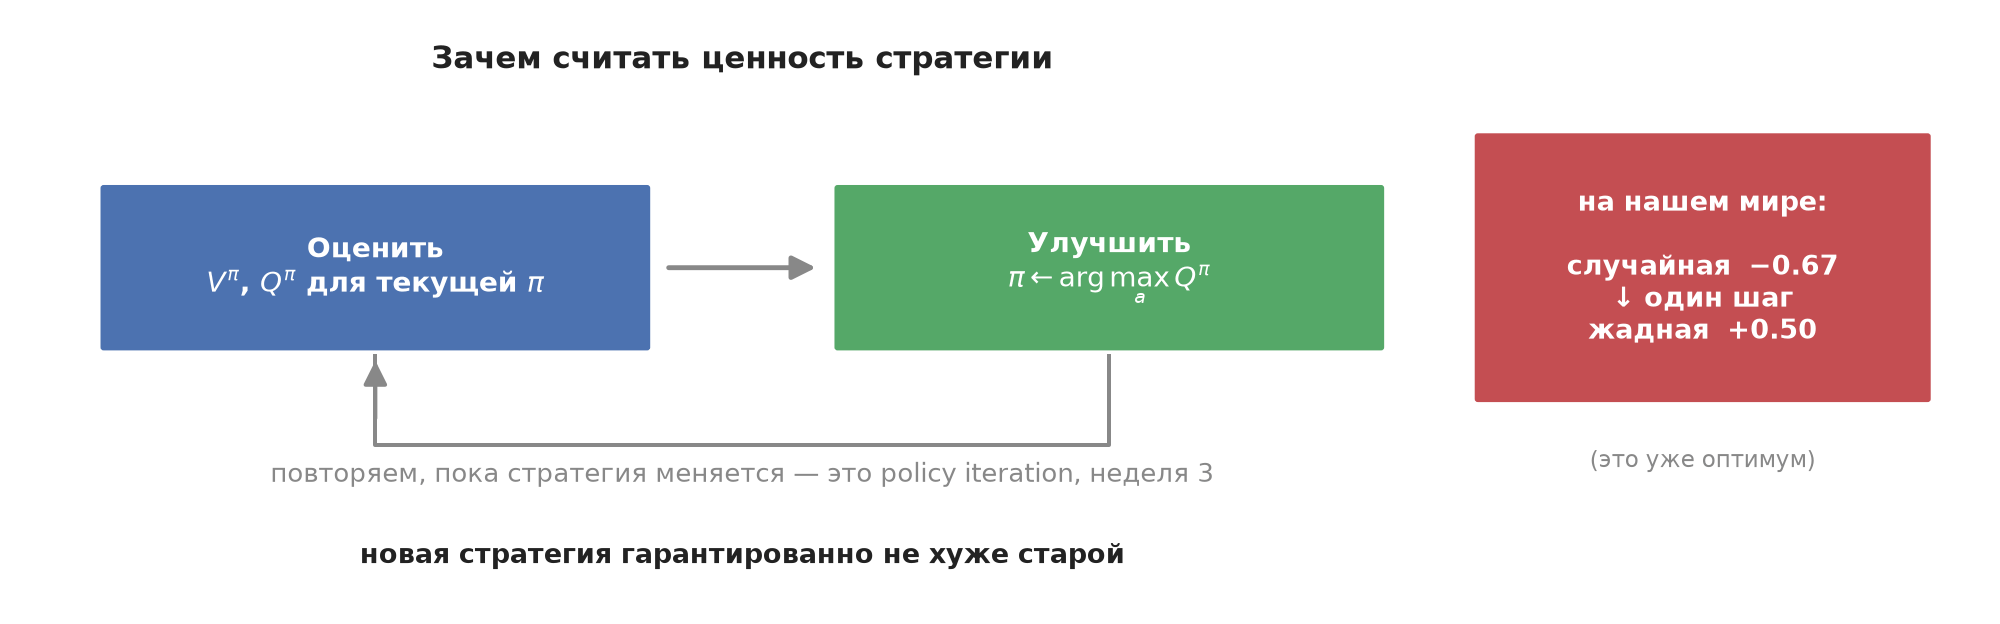

Отсюда же видно, как два алгоритма сходятся в одну точку. При $\varepsilon \to 0$ выбранное действие $a'$ — почти всегда $\arg\max$, и цель SARSA превращается в цель Q-learning:

$$r + \gamma\, Q(s',\ \underbrace{a'}_{\to\ \arg\max}) \;\;\xrightarrow{\;\varepsilon \to 0\;}\;\; r + \gamma \max_{a'} Q(s', a')$$

Правило из этого: гасите $\varepsilon$ со временем — SARSA тоже придёт к $Q^*$ (начало этого пути вы видели в эксперименте с $\varepsilon = 0.01$); держите $\varepsilon$ постоянным — получите ровно обещанное: ценность своей $\varepsilon$-жадной стратегии.

**Одной строкой:** SARSA — это policy iteration по попыткам: обновление минимизирует TD-ошибку (оценка стратегии), а argmax внутри $\varepsilon$-жадного выбора делает стратегию жаднее (улучшение).

## 7. ⏱ Expected SARSA и завышающий максимум

### 7.1 Expected SARSA: среднее вместо жребия

SARSA берёт в цель одно случайное $a'$ — лишний шум. Но мы знаем, *с какими вероятностями* стратегия выбирает действия, — можно усреднить по всем сразу:

$$
\text{цель} = r + \gamma \sum_{a'} \pi(a' \mid s')\, Q(s', a')
$$

🔁 Это ровно связь $V^\pi(s') = \sum_{a'} \pi(a' \mid s')\, Q^\pi(s', a')$ из лекции 2. В коде — третья ветка `td_control`.

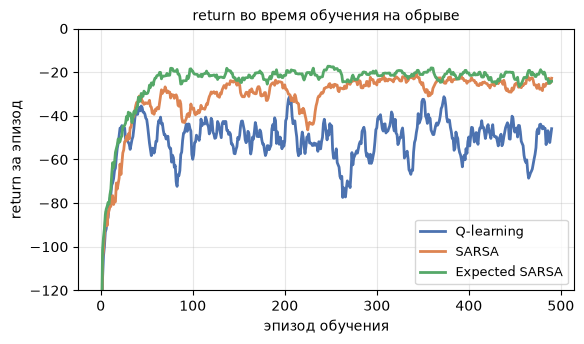

    Q-learning: return при обучении (последние 100 эпизодов) -50.2;  жадный путь: 13 шагов
         SARSA: return при обучении (последние 100 эпизодов) -25.3;  жадный путь: 17 шагов
Expected SARSA: return при обучении (последние 100 эпизодов) -21.9;  жадный путь: 15 шагов


In [8]:
runs["Expected SARSA"] = [td_control(cliff, "expected sarsa", seed=seed) for seed in range(10)]
plot_curves({name: [ret for _, ret in r] for name, r in runs.items()}, title="return во время обучения на обрыве")
plt.show()
for name, r in runs.items():
    path = greedy_path(r[SHOW][0])
    steps = f"{len(path) - 1} шагов" if path[-1] == CLIFF_GOAL else "до G не доходит"
    print(f"{name:>14}: return при обучении (последние 100 эпизодов) "
          f"{np.mean([ret[-100:].mean() for _, ret in r]):+.1f};  жадный путь: {steps}")

Expected SARSA набирает при обучении больше всех — около $-22$: цель у него та же, что у SARSA, но без шума от случайного $a'$. И путь он выбирает примечательный — **средний ряд, 15 шагов**: компромисс между краем и дальним обходом.

### 7.2 Максимум завышает

Житейский факт, знакомый каждому: ресторан с рейтингом 5.0 по трём отзывам при визите обычно оказывается хуже своего рейтинга. Оценка по трём отзывам шумная, у кого-то из обычных ресторанов она случайно завысилась — и именно он выиграл конкурс рейтингов. **Выбирая лучшего по шумным оценкам, выбираешь не только качество, но и везение** — поэтому выбранный в среднем разочаровывает.

**Вопрос 8 (голосуем).** Проверим это числом. Десять игровых автоматов, у **всех** средний выигрыш ровно 0 — они идеально одинаковые. Сыграем на каждом по 10 раз и выберем автомат с лучшей оценкой. Его оценка в среднем: $\approx 0$, заметно больше $0$, меньше $0$ или ровно $0$?

In [9]:
rng = np.random.default_rng(0)
wins = rng.normal(0, 1, size=(10_000, 10, 10))        # 10 000 повторов опыта: 10 автоматов × 10 игр

Q_one = wins.mean(axis=2)                             # одна оценка по всем играм
Q_A, Q_B = wins[..., :5].mean(axis=2), wins[..., 5:].mean(axis=2)   # две независимые половины
best_by_A = Q_A.argmax(axis=1)

print(f"одна таблица:  max_a Q(a)           = {Q_one.max(axis=1).mean():+.2f}   (истина 0)")
print(f"две таблицы:   Q_B(argmax_a Q_A(a)) = {Q_B[np.arange(len(Q_B)), best_by_A].mean():+.2f}")

одна таблица:  max_a Q(a)           = +0.49   (истина 0)
две таблицы:   Q_B(argmax_a Q_A(a)) = -0.00


Вот один такой опыт на картинке: все автоматы в среднем по нулям, но у «лучшего» оценка около $+0.5$ — это везение, а не качество:

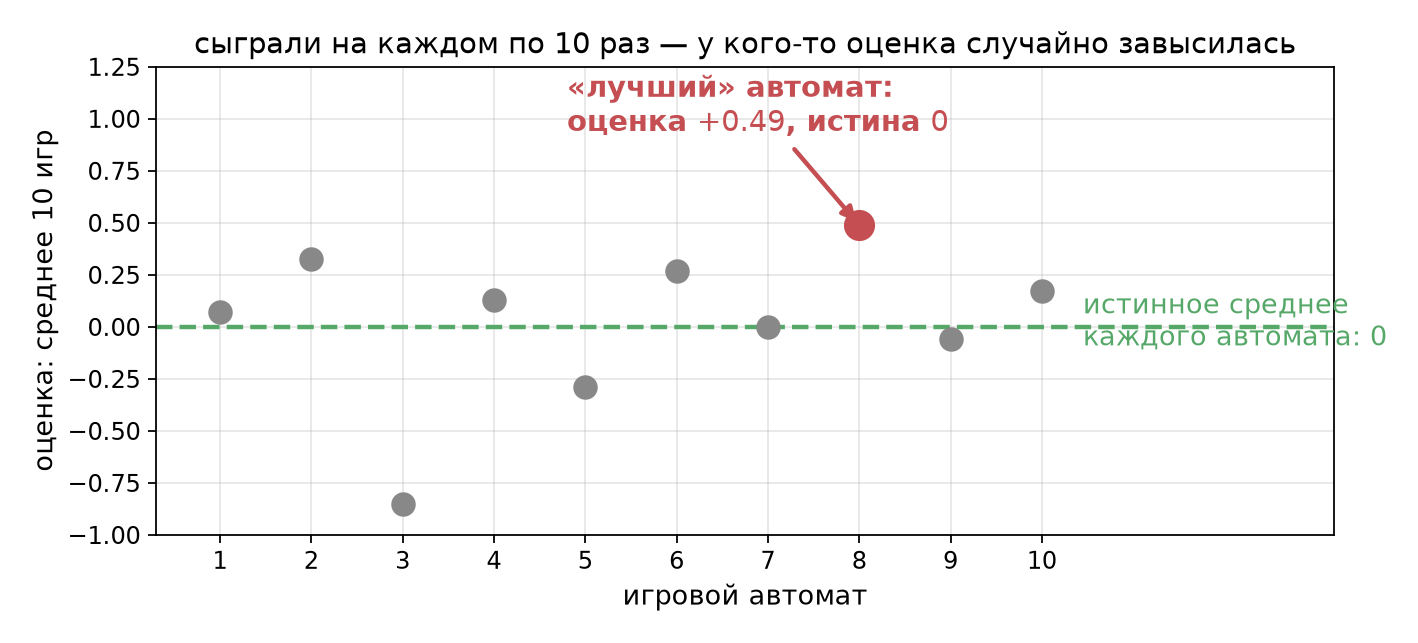

При чём тут Q-learning? В его цели $r + \gamma \max_{a'} Q(s',a')$ стоит ровно такой же «конкурс рейтингов» — выбор лучшего действия по шумным оценкам, на **каждом** шаге обучения. Поэтому его оценки всегда немного льстят себе. В нашем маленьком мире это доли сотых и тонет в шуме, но чем шумнее оценки и чем больше действий, тем сильнее накапливается завышение.

Лечение — то же, что у людей: **независимое второе мнение**. Заведём две таблицы, $Q_A$ и $Q_B$, обученные на разных шагах. Пусть $Q_A$ только **выбирает** лучшее действие, а оценку для цели даёт $Q_B$: везение таблицы $A$ — её личное, у $B$ на том же действии оно не повторится:

$$
\text{цель} = r + \gamma\, Q_B\big(s',\ \arg\max_{a'} Q_A(s', a')\big)
$$

На каждом шаге монетка решает, какую таблицу обновлять, и они меняются ролями. Это **Double Q-learning** — в опыте с автоматами «второе мнение» дало честный $0.00$ вместо $+0.49$. В теме DQN та же идея станет Double DQN.

**Одной строкой:** усредняй по стратегии вместо жребия (Expected SARSA); выбирай одной таблицей, оценивай другой (Double Q-learning).

## 8. Итоги и где это работает

Четыре алгоритма сегодняшней и прошлой лекций различаются **только целью обновления** — само обновление всегда одно: новая оценка = старая + $\alpha$ · (цель − старая).

| Алгоритм | Цель | Что выучит | Роли стратегии |
|---|---|---|---|
| Q-learning | $r + \gamma \max_{a'} Q(s',a')$ | $Q^*$ | разные — off-policy |
| SARSA | $r + \gamma\, Q(s',a')$, $a'$ — сделанное | $Q^\pi$ своей $\varepsilon$-жадной | совпадают — on-policy |
| Expected SARSA | $r + \gamma \sum_{a'} \pi(a'|s')\, Q(s',a')$ | $Q^\pi$, без шума от $a'$ | совпадают — on-policy |
| Double Q-learning | $r + \gamma\, Q_B(s', \arg\max_{a'} Q_A(s',a'))$ | $Q^*$ без завышения | разные — off-policy |

1. **У стратегии две роли** — кто ходит и чью ценность учим. Совпали — on-policy, разошлись — off-policy.
2. **На обрыве разница видна глазом:** Q-learning идёт по краю (13 шагов, при обучении $\approx -50$), SARSA — в обход (17 шагов, $\approx -25$). Кто прав — зависит от того, будет ли агент ошибаться после обучения.
3. **Off-policy учится на чужих данных** — даже когда все данные собраны случайной стратегией, Q-learning нашёл $V^*$. Отсюда буфер опыта в DQN.
4. **Максимум шумных оценок завышен** — лечится двумя таблицами (Double Q-learning).
5. **SARSA — это policy iteration по попыткам**: обновление минимизирует TD-ошибку $(\text{цель} - Q)^2$ — это шаг оценки стратегии (и будущий loss в DQN), а argmax внутри $\varepsilon$-жадного выбора — шаг улучшения; при $\varepsilon \to 0$ цель SARSA переходит в цель Q-learning.

**Где это работает в жизни.** Табличные TD-алгоритмы и их родня — не только учебные игрушки:

* **$\varepsilon$-жадность и бандиты** — выбор обложек и баннеров в рекомендательных сервисах: Netflix подбирает заставки фильмов контекстными бандитами. С этого начнётся семинар.
* **Диспетчеризация такси** — DiDi использовала TD-оценку ценности, решая, какому водителю отдать заказ; семинарское такси — младший брат этой задачи.
* **Умные светофоры** — адаптивное управление перекрёстками на Q-learning и SARSA: одно из самых исследуемых применений, испытания на реальных перекрёстках уже идут.
* Когда состояний слишком много для таблицы, её место займёт нейросеть — с этого начнётся Deep RL в нашем курсе.

Словарь лекции: **SARSA, пятёрка $(s,a,r,s',a')$, стратегия поведения, целевая стратегия, on-policy, off-policy, оценка стратегии (policy evaluation), generalized policy iteration, TD-ошибка как функция потерь, semi-gradient, Expected SARSA, смещение максимума, Double Q-learning**.

## Литература

* R. Sutton, A. Barto. *Reinforcement Learning: An Introduction* — [бесплатный PDF](http://incompleteideas.net/book/the-book-2nd.html). Разделы 6.4–6.7: SARSA, Q-learning, Expected SARSA, смещение максимума и Double Q-learning; пример 6.6 — наш обрыв.
* [Artwork Personalization at Netflix](https://netflixtechblog.com/artwork-personalization-c589f074ad76) — контекстные бандиты выбирают заставки фильмов.
* Z. Xu и др. [Large-Scale Order Dispatch in On-Demand Ride-Hailing Platforms](https://dl.acm.org/doi/10.1145/3219819.3219824) (KDD 2018) — TD-оценка ценности в диспетчеризации DiDi.
* [Понимание Q-learning, проблема «Прогулка по скале»](https://habr.com/ru/articles/443240/) — Хабр, тот же обрыв.
* D. Silver. [UCL Course on RL](https://www.davidsilver.uk/teaching/), лекция 5 (model-free control): on/off-policy.
* [Учебник по машинному обучению ШАД](https://education.yandex.ru/handbook/ml/article/obuchenie-s-podkrepleniem) — глава про обучение с подкреплением.

## На семинаре и дома

* **Семинар**: SARSA и Q-learning своими руками — на обрыве и в Taxi-v3.
* **Квиз** по лекции 4 — на [странице квизов](https://ilyachichkanov.github.io/Reinforcement-learning/). Там же — [песочница](https://ilyachichkanov.github.io/Reinforcement-learning/lecture04.html#sandbox): проверьте, при каком $\varepsilon$ SARSA решится идти по краю.
* Домашнее задание блока 2 выйдет после следующей лекции.